In [1]:

import pandas as pd

normal = pd.read_csv("../data/ptbdb_normal.csv", header=None)
abnormal = pd.read_csv("../data/ptbdb_abnormal.csv", header=None)

df = pd.concat([normal, abnormal], ignore_index=True)

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [2]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [3]:
print(X.shape)
print(X_pca.shape)

(14552, 187)
(14552, 2)


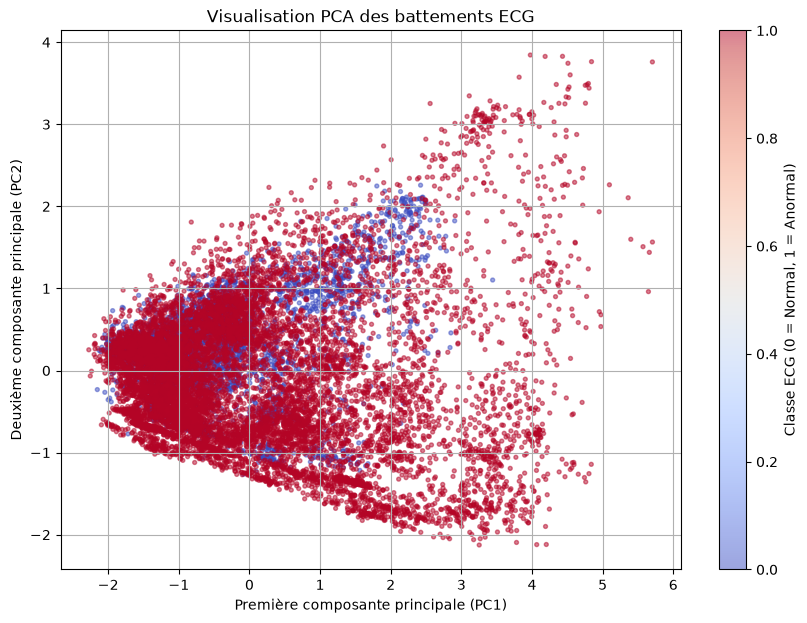

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.5,
    s=8
)

plt.xlabel("Première composante principale (PC1)")
plt.ylabel("Deuxième composante principale (PC2)")
plt.title("Visualisation PCA des battements ECG")

plt.colorbar(label="Classe ECG (0 = Normal, 1 = Anormal)")
plt.grid(True)
plt.show()

### On observe trois choses importantes :

### 1. Les deux classes se chevauchent fortement.

Les points bleus (ECG normaux) et rouges (ECG anormaux) occupent largement les mêmes régions.

Cela signifie que la PCA en deux dimensions ne permet pas de séparer clairement les deux classes.

### 2. Les ECG anormaux sont plus dispersés.

On observe beaucoup de points rouges dans les régions extrêmes, notamment à droite du graphique (PC1 supérieur à 3) et en bas (PC2 inférieur à -1,5).

Cela suggère une plus grande diversité des formes des ECG anormaux.

### 3. Les ECG normaux semblent davantage concentrés.

Les points bleus sont surtout visibles dans la zone centrale, même s'ils se mélangent aux points rouges.

Attention : comme nous avons davantage d'ECG anormaux dans notre dataset, leur couleur domine naturellement le graphique.

In [5]:
print(pca.explained_variance_ratio_)

[0.38866927 0.12765525]


In [6]:
print(pca.explained_variance_ratio_.sum() * 100)

51.63245187361007


### Conclusion de l'analyse PCA

L'analyse en composantes principales (PCA) a permis de projeter les 187 caractéristiques des battements ECG dans un espace à deux dimensions.

Les deux premières composantes principales expliquent respectivement **38,87 %** et **12,77 %** de la variance, soit **51,63 % au total**.

La visualisation révèle un chevauchement important entre les battements normaux et anormaux, bien que les battements anormaux semblent davantage dispersés.

Cette représentation ne permet donc pas de distinguer clairement les deux classes. Cependant, les caractéristiques originales peuvent contenir des informations discriminantes qui ne sont pas visibles dans cette projection.

mesurer combien de composantes PCA sont nécessaires pour conserver 90 % ou 95 % de la variance.

In [7]:
pca_complete = PCA()
pca_complete.fit(X)


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [8]:
import numpy as np

variance_cumulee = np.cumsum(pca_complete.explained_variance_ratio_)

In [11]:
variance_cumulee

array([0.38866927, 0.51632452, 0.5843503 , 0.62572377, 0.66006191,
       0.68429597, 0.70655093, 0.7279173 , 0.74671717, 0.7623641 ,
       0.77657203, 0.79011239, 0.80279532, 0.81484221, 0.82578482,
       0.83638642, 0.84587128, 0.85522401, 0.86409562, 0.87211502,
       0.87968582, 0.88693389, 0.89370251, 0.89986108, 0.9056979 ,
       0.91114959, 0.91604719, 0.9207642 , 0.9251316 , 0.92935421,
       0.93335555, 0.93713839, 0.94063643, 0.94391283, 0.94698566,
       0.94980606, 0.95244078, 0.95480431, 0.95700755, 0.95913873,
       0.96102353, 0.96276042, 0.96444478, 0.96599587, 0.96747885,
       0.96885853, 0.97012859, 0.97137937, 0.97251255, 0.97361349,
       0.97467222, 0.97566736, 0.97660769, 0.97751396, 0.97836209,
       0.97915188, 0.97992047, 0.9806355 , 0.98130954, 0.98195257,
       0.98258439, 0.98319812, 0.98377768, 0.98431635, 0.98482956,
       0.98533644, 0.98583265, 0.98630844, 0.98675891, 0.98719956,
       0.98762125, 0.98802331, 0.98840564, 0.988778  , 0.98913

In [12]:
n_90 = np.searchsorted(variance_cumulee, 0.90) + 1
n_95 = np.searchsorted(variance_cumulee, 0.95) + 1

print("Composantes pour 90 % :", n_90)
print("Composantes pour 95 % :", n_95)

Composantes pour 90 % : 25
Composantes pour 95 % : 37


Avec seulement 37 composantes au lieu de 187, nous conservons au moins 95 % de la variance des données.

Cela représente une réduction d'environ 80,2 % du nombre de caractéristiques !

Attention, conserver 95 % de la variance ne garantit pas de conserver 95 % des informations utiles à la classification.

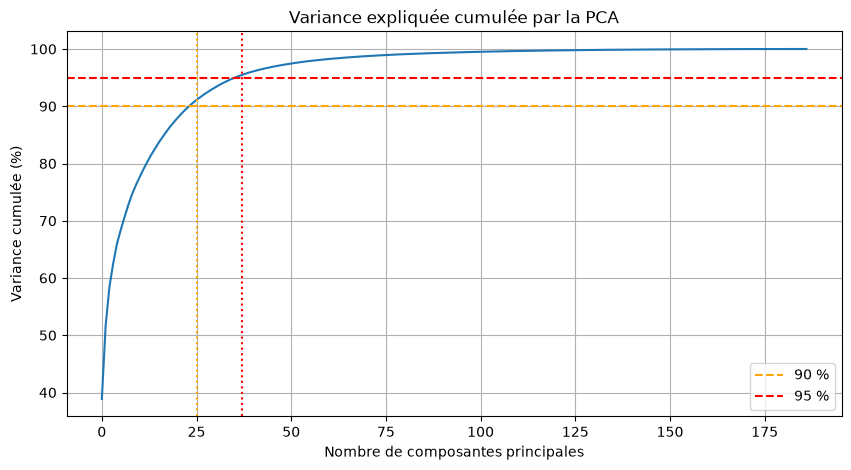

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(variance_cumulee * 100)

plt.axhline(y=90, color="orange", linestyle="--", label="90 %")
plt.axhline(y=95, color="red", linestyle="--", label="95 %")

plt.axvline(x=25, color="orange", linestyle=":")
plt.axvline(x=37, color="red", linestyle=":")

plt.xlabel("Nombre de composantes principales")
plt.ylabel("Variance cumulée (%)")
plt.title("Variance expliquée cumulée par la PCA")

plt.legend()
plt.grid(True)
plt.show()

1. Interprétation du graphique
On observe trois phases :
- Au début, la courbe augmente rapidement. Les premières composantes capturent une grande partie de la variance.
- Vers 25 composantes, nous atteignons 90 % de variance expliquée.
- Vers 37 composantes, nous atteignons 95 %. Ensuite, la courbe s'aplatit progressivement.
Cela signifie que les 187 caractéristiques de nos ECG contiennent une certaine redondance : nous pouvons représenter une grande partie de leur variabilité avec beaucoup moins de dimensions.

### Conclusion de l'analyse PCA

L'analyse en composantes principales (PCA) a permis d'étudier la structure des battements ECG à partir de leurs 187 caractéristiques.

**Principaux résultats :**

- Les deux premières composantes expliquent **51,63 %** de la variance totale.
- La projection en deux dimensions révèle un chevauchement important entre les ECG normaux et anormaux.
- **25 composantes** suffisent pour conserver au moins 90 % de la variance.
- **37 composantes** suffisent pour conserver au moins 95 % de la variance.

Ces résultats montrent qu'une réduction importante de la dimension des données est possible tout en préservant l'essentiel de leur variabilité statistique.

Cependant, la variance conservée ne garantit pas la préservation des informations nécessaires à la classification.

La prochaine étape consistera à comparer les performances des modèles de classification entraînés sur les **187 caractéristiques originales** et sur les **37 composantes PCA**.